In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [29]:
df = pd.read_csv("UCI_Credit_Card.csv")
df = df.rename(columns={'default.payment.next.month': 'def_pay', 
                        'PAY_0': 'PAY_1'})

In [30]:
# Drop "ID" column.
data=df.drop(['ID'], axis=1)
print(f"There are {data.duplicated().sum()} duplicate rows in the data set.")
# Duplicate rows are removed.
df = df[~data.duplicated()]

There are 35 duplicate rows in the data set.


In [31]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,def_pay
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [32]:
#  Marital status (1 = married; 2 = single; 3 = others).
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      323
0       54
Name: count, dtype: int64

In [33]:
df.loc[df.MARRIAGE == 0, 'MARRIAGE'] = 3
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64

In [34]:
# Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
df.EDUCATION.value_counts() 

fil = (df.EDUCATION == 5) | (df.EDUCATION == 6) | (df.EDUCATION == 0)
df.loc[fil, 'EDUCATION'] = 4
df.EDUCATION.value_counts()

EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

In [35]:
new_df = df.drop(columns=['BILL_AMT1', 'PAY_AMT6','def_pay','PAY_1','PAY_2'])
new_df = new_df.rename(columns={'PAY_3': 'July_Status', 
                        'PAY_4': 'June_Status',
                        'PAY_5': 'May_Status',
                        'PAY_6': 'April_Status',
                        'BILL_AMT2': 'August_Bill',
                        'BILL_AMT3': 'July_Bill',
                        'BILL_AMT4': 'June_Bill',
                        'BILL_AMT5': 'May_Bill',
                        'BILL_AMT6': 'April_Bill',
                        'PAY_AMT1': 'August_Pay',
                        'PAY_AMT2': 'July_Pay',
                        'PAY_AMT3': 'June_Pay',
                        'PAY_AMT4': 'May_Pay',
                        'PAY_AMT5': 'April_Pay'})

new_df.drop(columns=['ID'], inplace=True)

new_df['SEX'] = new_df.SEX.astype('category')
new_df['EDUCATION'] = new_df.EDUCATION.astype('category')
new_df['MARRIAGE'] = new_df.MARRIAGE.astype('category')
new_df['July_Status'] = new_df.July_Status.astype('category')
new_df['June_Status'] = new_df.June_Status.astype('category')
new_df['May_Status'] = new_df.May_Status.astype('category')
new_df['April_Status'] = new_df.April_Status.astype('category')

In [36]:
new_df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,July_Status,June_Status,May_Status,April_Status,August_Bill,July_Bill,June_Bill,May_Bill,April_Bill,August_Pay,July_Pay,June_Pay,May_Pay,April_Pay
0,20000.0,2,2,1,24,-1,-1,-2,-2,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0
1,120000.0,2,2,2,26,0,0,0,2,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0
2,90000.0,2,2,2,34,0,0,0,0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0
3,50000.0,2,2,1,37,0,0,0,0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0
4,50000.0,1,2,1,57,-1,0,0,0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0


# Base Model Linear Regression

In [37]:
X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['August_Pay']), new_df['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16775.747652828817


# Feature Engineering

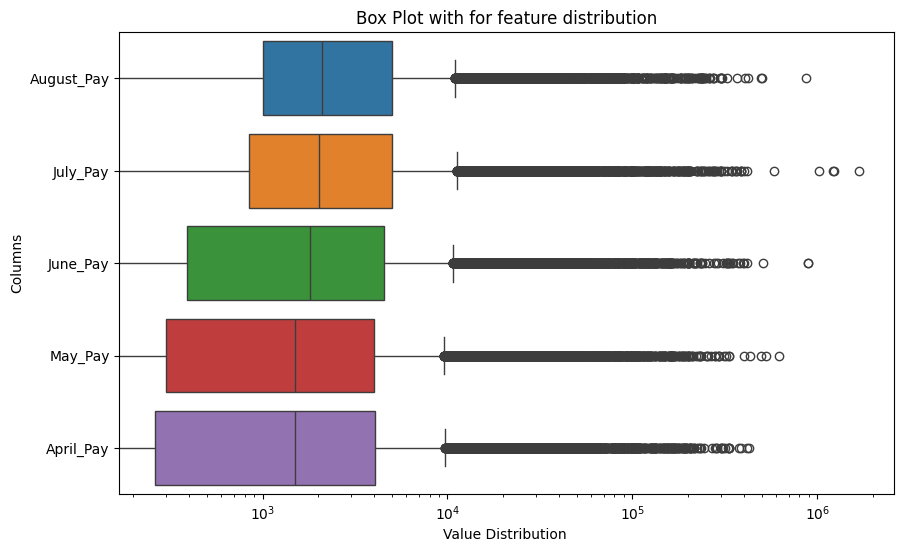

In [24]:
# Select numerical columns
num_cols = ['August_Pay', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=new_df[num_cols], orient='h')
ax.set_xscale('log')
plt.xlabel("Value Distribution ")
plt.ylabel("Columns")
plt.title("Box Plot with for feature distribution")
plt.show()

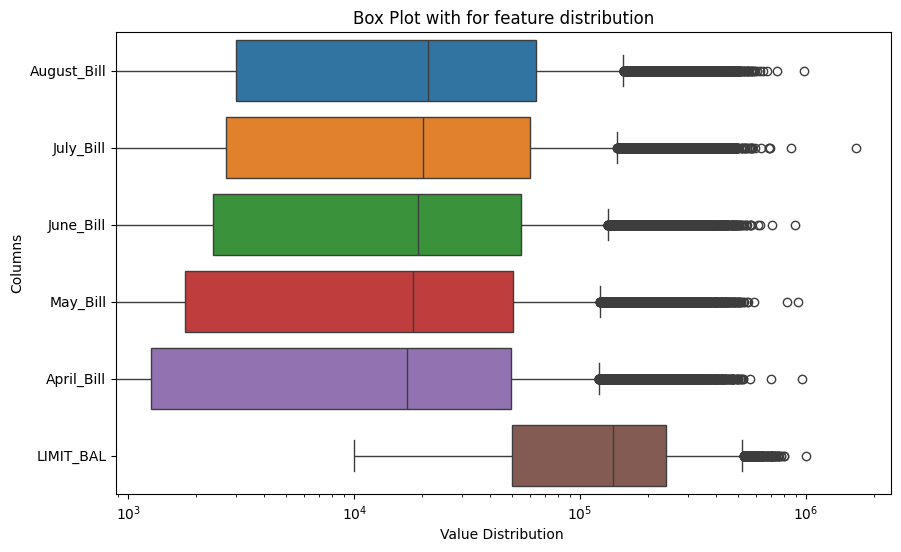

In [25]:
# Select numerical columns
num_cols = ['August_Bill', 'July_Bill', 'June_Bill', 'May_Bill', 'April_Bill',
            'LIMIT_BAL']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=new_df[num_cols], orient='h')
ax.set_xscale('log')
plt.xlabel("Value Distribution ")
plt.ylabel("Columns")
plt.title("Box Plot with for feature distribution")
plt.show()

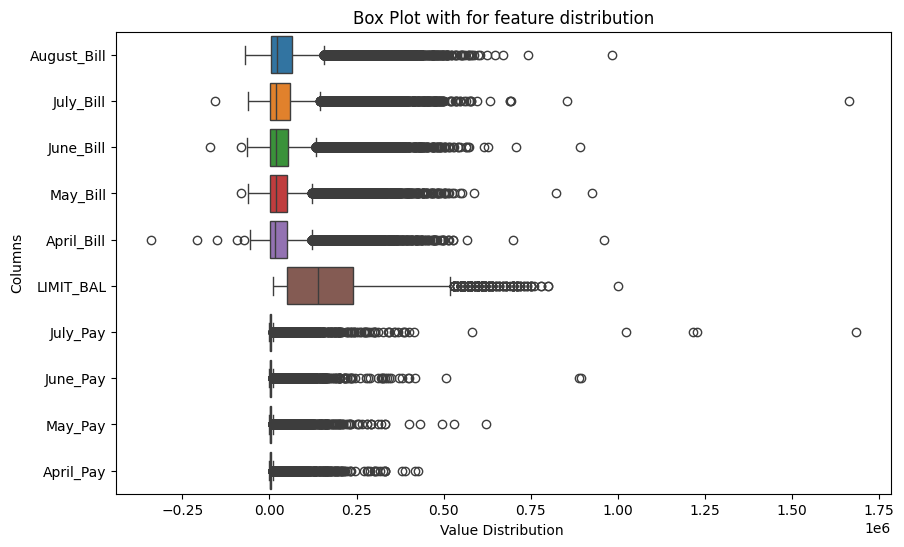

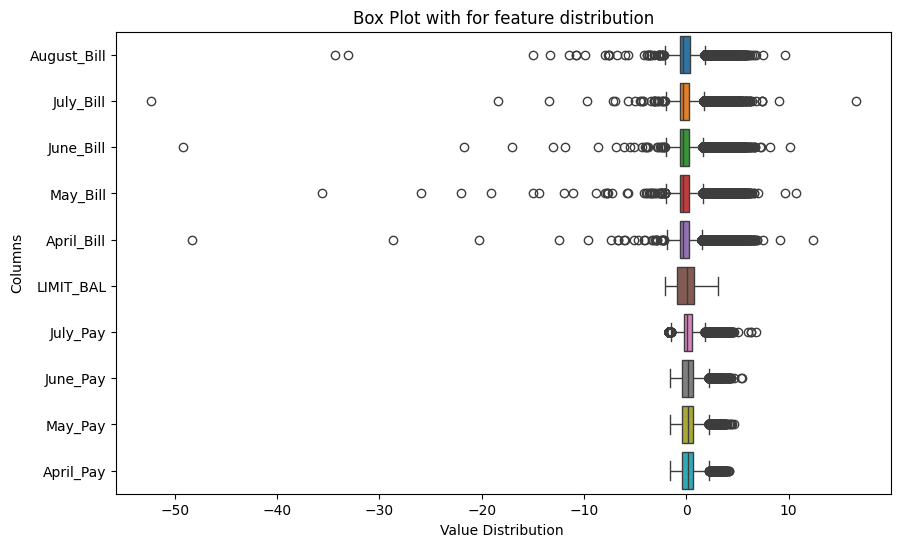

In [26]:
from sklearn.preprocessing import PowerTransformer

# Select numerical columns
num_cols = ['August_Bill', 'July_Bill', 'June_Bill', 'May_Bill', 'April_Bill', 'LIMIT_BAL', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay']

scaled_new_df = new_df.copy()

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=scaled_new_df[num_cols], orient='h')
# ax.set_xscale('log')
plt.xlabel("Value Distribution ")
plt.ylabel("Columns")
plt.title("Box Plot with for feature distribution")
plt.show()

# Initialize RobustScaler
power_transformer = PowerTransformer(method="yeo-johnson")

scaled_new_df["LIMIT_BAL"]= power_transformer.fit_transform(scaled_new_df[["LIMIT_BAL"]])
scaled_new_df["August_Bill"]= power_transformer.fit_transform(scaled_new_df[["August_Bill"]])
scaled_new_df["July_Bill"]= power_transformer.fit_transform(scaled_new_df[["July_Bill"]])
scaled_new_df["June_Bill"]= power_transformer.fit_transform(scaled_new_df[["June_Bill"]])
scaled_new_df["May_Bill"]= power_transformer.fit_transform(scaled_new_df[["May_Bill"]])
scaled_new_df["April_Bill"]= power_transformer.fit_transform(scaled_new_df[["April_Bill"]])
scaled_new_df["July_Pay"]= power_transformer.fit_transform(scaled_new_df[["July_Pay"]])
scaled_new_df["June_Pay"]= power_transformer.fit_transform(scaled_new_df[["June_Pay"]])
scaled_new_df["May_Pay"]= power_transformer.fit_transform(scaled_new_df[["May_Pay"]])
scaled_new_df["April_Pay"]= power_transformer.fit_transform(scaled_new_df[["April_Pay"]])

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=scaled_new_df[num_cols], orient='h')
# ax.set_xscale('log')
plt.xlabel("Value Distribution ")
plt.ylabel("Columns")
plt.title("Box Plot with for feature distribution")
plt.show()


In [27]:
X_train, X_test, y_train, y_test = train_test_split(scaled_new_df.drop(columns=['August_Pay']), scaled_new_df['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 19665.222418624955
